HANDWRITTEN DIGIT RECOGNITION
--------------------------------
Dataset loaded successfully!
Total images: 1797
Image size: 8 x 8 pixels
Number of features: 64
Number of classes: 10


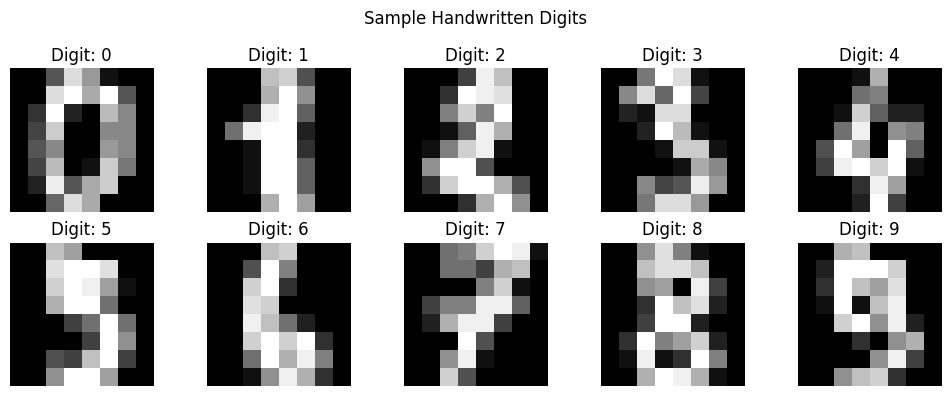


TRAINING AND TESTING
--------------------
Training images: 1437
Testing images: 360

Model trained successfully!

MODEL ACCURACY
--------------
Accuracy: 96.39 %

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        36
           1       0.92      0.97      0.95        36
           2       1.00      0.97      0.99        35
           3       0.97      0.97      0.97        37
           4       0.97      1.00      0.99        36
           5       0.97      1.00      0.99        37
           6       1.00      0.97      0.99        36
           7       0.92      1.00      0.96        36
           8       0.94      0.86      0.90        35
           9       0.97      0.92      0.94        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360


CONFUSION MATRIX
---------------

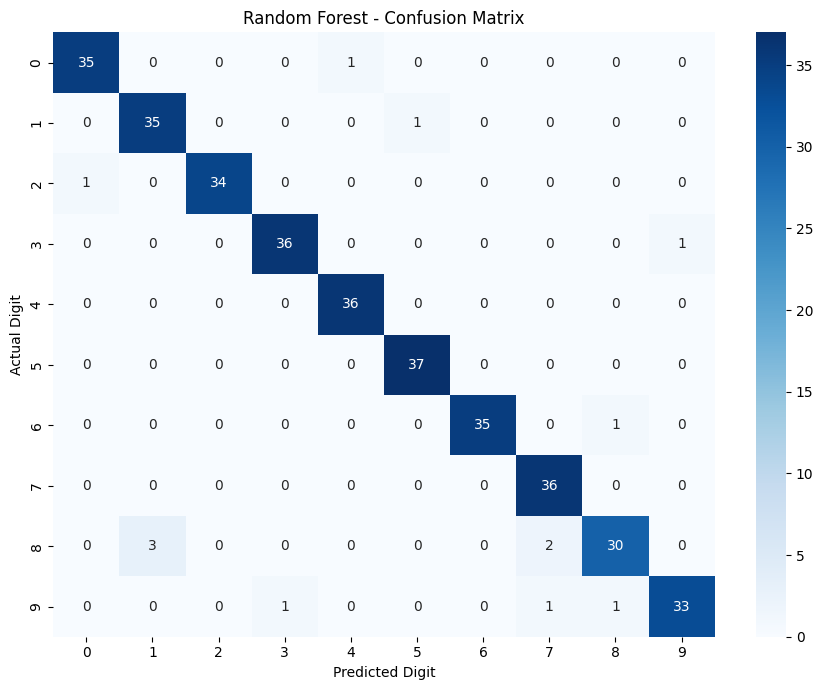

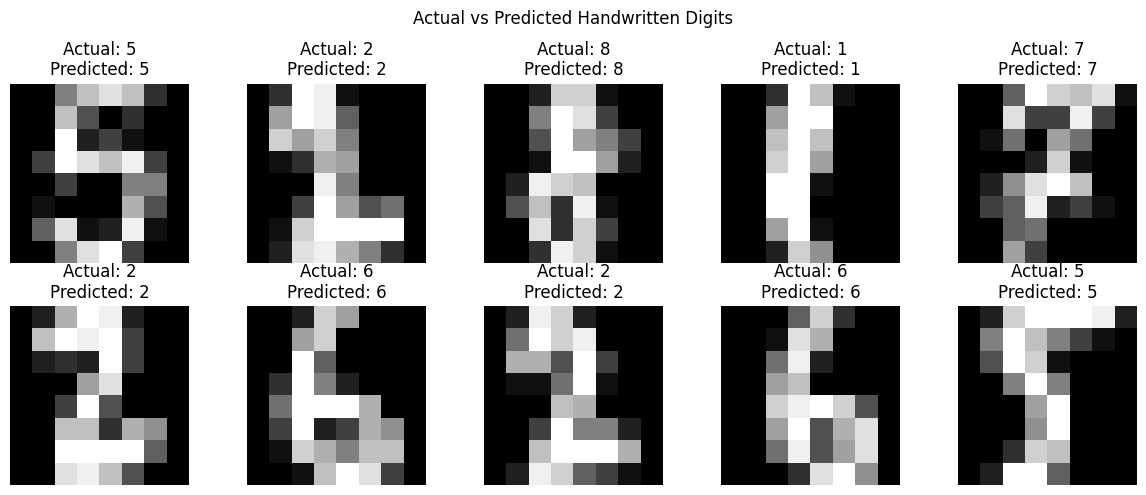


PROJECT EXECUTED SUCCESSFULLY!
Algorithm: Random Forest Classifier
Dataset: Handwritten Digits Dataset
Total Images: 1797
Training Images: 1437
Testing Images: 360
Final Accuracy: 96.39 %

All output files saved in outputs folder!


In [ ]:

# ==========================================================
# PROJECT: HANDWRITTEN DIGIT RECOGNITION
# ALGORITHM: RANDOM FOREST CLASSIFIER
# ==========================================================

# 1. Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# 2. Load the handwritten digits dataset

digits = load_digits()

X = digits.data
y = digits.target

print("HANDWRITTEN DIGIT RECOGNITION")
print("--------------------------------")

print("Dataset loaded successfully!")
print("Total images:", len(X))
print("Image size: 8 x 8 pixels")
print("Number of features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))

# 3. Display sample handwritten digits

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(digits.images[i], cmap='gray')
    plt.title("Digit: " + str(digits.target[i]))
    plt.axis('off')

plt.suptitle("Sample Handwritten Digits")
plt.tight_layout()
plt.show()

# 4. Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTRAINING AND TESTING")
print("--------------------")
print("Training images:", len(X_train))
print("Testing images:", len(X_test))

# 5. Create Random Forest Classifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# 6. Train the model

model.fit(X_train, y_train)

print("\nModel trained successfully!")

# 7. Predict handwritten digits

y_pred = model.predict(X_test)

# 8. Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("\nMODEL ACCURACY")
print("--------------")
print("Accuracy:", round(accuracy * 100, 2), "%")

# 9. Display classification report

report = classification_report(y_test, y_pred)

print("\nCLASSIFICATION REPORT")
print("---------------------")
print(report)

# 10. Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("\nCONFUSION MATRIX")
print("----------------")
print(cm)

# 11. Create output folder

os.makedirs("outputs", exist_ok=True)

# 12. Save predictions in CSV file

results = pd.DataFrame({
    "Actual Digit": y_test,
    "Predicted Digit": y_pred
})

results.to_csv("outputs/predictions.csv", index=False)

# 13. Save classification report

with open("outputs/classification_report.txt", "w") as f:
    f.write("HANDWRITTEN DIGIT RECOGNITION\n")
    f.write("Algorithm: Random Forest Classifier\n")
    f.write("Accuracy: " + str(round(accuracy * 100, 2)) + "%\n\n")
    f.write(report)

# 14. Plot confusion matrix

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=digits.target_names,
    yticklabels=digits.target_names
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()

plt.savefig("outputs/confusion_matrix.png")
plt.show()

# 15. Display actual and predicted digits

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(8, 8), cmap="gray")
    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )
    plt.axis("off")

plt.suptitle("Actual vs Predicted Handwritten Digits")
plt.tight_layout()

plt.savefig("outputs/predicted_digits.png")
plt.show()

# 16. Save trained machine learning model

joblib.dump(model, "outputs/random_forest_model.pkl")

# 17. Save dataset as CSV

dataset = pd.DataFrame(
    X,
    columns=[f"pixel_{i}" for i in range(64)]
)

dataset["Digit"] = y

dataset.to_csv("outputs/digits_dataset.csv", index=False)

# 18. Save accuracy separately

with open("outputs/accuracy.txt", "w") as f:
    f.write("Model Accuracy: " + str(round(accuracy * 100, 2)) + "%")

# 19. Display final results

print("\n===================================")
print("PROJECT EXECUTED SUCCESSFULLY!")
print("===================================")

print("Algorithm: Random Forest Classifier")
print("Dataset: Handwritten Digits Dataset")
print("Total Images:", len(X))
print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))
print("Final Accuracy:", round(accuracy * 100, 2), "%")

print("\nAll output files saved in outputs folder!")


In [ ]:

import shutil
from google.colab import files

# Create ZIP file containing all project outputs
shutil.make_archive(
    "ML_Results",
    "zip",
    "outputs"
)

# Download ZIP file to computer
files.download("ML_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import matplotlib.pyplot as plt
import os
from sklearn.datasets import load_digits

digits = load_digits()

# Create folder for digit images
os.makedirs("outputs/digit_images", exist_ok=True)

# Save sample images of digits 0 to 9
for digit in range(10):

    index = list(digits.target).index(digit)

    plt.figure(figsize=(3, 3))
    plt.imshow(digits.images[index], cmap="gray")
    plt.title("Handwritten Digit: " + str(digit))
    plt.axis("off")

    plt.savefig(
        f"outputs/digit_images/digit_{digit}.png",
        bbox_inches="tight"
    )

    plt.close()

print("All 10 digit images saved successfully!")


All 10 digit images saved successfully!


In [ ]:

import shutil
from google.colab import files

shutil.make_archive("ML_Results", "zip", "outputs")

files.download("ML_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>